# Анализ данных розничной торговли с помощью множественной регрессии

В ноутбуке проводится предварительная проверка данных, сравниваются три модели с ценой одного конкурента и оценивается множественная модель со всеми тремя ценами. В итоговой модели шесть факторов: число покупателей, три цены конкурентов, вес товара и число фотографий в карточке товара. Работа описывает статистические связи, а не причинные эффекты.

В таблице 676 наблюдений по 52 товарам. Поскольку каждый товар встречается в разные месяцы, стандартные ошибки группируются по `product_id`.


## 1. Подготовка данных, очистка и выбор признаков

Проверяются пропуски, полные дубликаты, повторы пары «товар—месяц» и допустимые значения. Для логарифмов все значения должны быть положительными; число фотографий включается в уровнях как счётный признак. В исходном файле нет пропусков и дубликатов, все значения используемых переменных допустимы, поэтому все 676 строк сохранены. Крайние цены автоматически не удаляются без подтверждения ошибки.

Пять исходных факторов связаны с вопросом работы: покупательский спрос (`customers`), цены конкурентов, масса товара (`product_weight_g`) и дополнительная характеристика товарной карточки (`product_photos_qty`). Число фотографий добавлено как контрольный признак полноты представления товара; оно варьируется от 1 до 8 и не является частью целевой цены. Его коэффициент проверяется, но значимость заранее не предполагается.

`unit_price` и `qty` не включаются, потому что `total_price` почти определяется их произведением. `lag_price` почти дублирует `unit_price` (r = 0,994), а смысл `s` в описании неоднозначен. Стоимость доставки `freight_price` хранится отдельно от `total_price`; к тому же в ней есть нулевое значение, поэтому она не подходит для той же логарифмической обработки. Категория товара потребовала бы восьми индикаторных столбцов для девяти категорий, а календарные признаки требуют отдельной модели сезонности.

Дополнительно проверяются `product_score` и `volume`. Оценка товара имеет узкий диапазон 3,3–4,5; объём частично дублирует массу. Их добавление по одному к итоговой модели не улучшило скорректированный R², поэтому они оставлены за рамками компактной спецификации. Подробная диагностика и результаты проверки приведены ниже.


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor

data = pd.read_csv(Path('retail_price.csv'))
source_rows = len(data)
source_columns = data.shape[1]
missing_all = int(data.isna().sum().sum())
exact_duplicates = int(data.duplicated().sum())
duplicate_product_month = int(data.duplicated(['product_id', 'month_year']).sum())

data_clean = data.drop_duplicates().copy()
columns = [
    'total_price', 'customers', 'comp_1', 'comp_2', 'comp_3',
    'product_weight_g', 'product_photos_qty', 'product_score', 'volume', 'product_id'
]
log_columns = [
    'total_price', 'customers', 'comp_1', 'comp_2', 'comp_3',
    'product_weight_g', 'volume'
]
positive_columns = log_columns + ['product_photos_qty', 'product_score']
descriptive_columns = [
    'total_price', 'customers', 'comp_1', 'comp_2', 'comp_3',
    'product_weight_g', 'product_photos_qty'
]
complete_data = data_clean[columns].dropna().copy()
nonpositive_mask = (complete_data[positive_columns] <= 0).any(axis=1)
model_data = complete_data.loc[~nonpositive_mask].copy()

quality_audit = pd.DataFrame([
    ('Строки / столбцы в исходном файле', f'{source_rows} / {source_columns}'),
    ('Пропущенные ячейки во всём файле', missing_all),
    ('Полные дубликаты строк', exact_duplicates),
    ('Повторные пары «товар—месяц»', duplicate_product_month),
    ('Строки с пропусками в выбранных полях и кандидатах', len(data_clean) - len(complete_data)),
    ('Строки с нулевыми или отрицательными значениями', int(nonpositive_mask.sum())),
    ('Исключено строк при подготовке модели', source_rows - len(model_data)),
    ('Осталось для моделей', len(model_data)),
], columns=['Проверка', 'Результат'])
display(quality_audit)

assert (model_data[positive_columns] > 0).all().all()
for column in log_columns:
    model_data[f'log_{column}'] = np.log(model_data[column])

print(f'Товарных групп: {model_data.product_id.nunique()}')
print(f'Диапазон product_photos_qty: {model_data.product_photos_qty.min()}–{model_data.product_photos_qty.max()} фотографий')
print(f'Нулевых значений freight_price: {int((data.freight_price == 0).sum())}')
print(f'Категорий товаров: {data.product_category_name.nunique()}')


,Проверка,Результат
0,Строки / столбцы в исходном файле,676 / 30
1,Пропущенные ячейки во всём файле,0
2,Полные дубликаты строк,0
3,Повторные пары «товар—месяц»,0
4,Строки с пропусками в выбранных полях и кандид...,0
5,Строки с нулевыми или отрицательными значениями,0
6,Исключено строк при подготовке модели,0
7,Осталось для моделей,676


Товарных групп: 52
Диапазон product_photos_qty: 1–8 фотографий
Нулевых значений freight_price: 1
Категорий товаров: 9


## 2. Описание данных и диагностика факторов

После проверки качества данных описываются переменные и распределение общей цены. Для предварительного поиска дублирующих признаков рассматриваются корреляции; затем мультиколлинеарность регрессоров оценивается по VIF. Корреляция сама по себе не служит основанием удалять важный для исследования фактор.


In [2]:
descriptive = model_data[descriptive_columns].agg(['mean', 'median', 'min', 'max']).T
descriptive.index = [
    'Общая цена', 'Число покупателей', 'Цена конкурента 1', 'Цена конкурента 2',
    'Цена конкурента 3', 'Вес товара, г', 'Число фотографий товара'
]
descriptive.columns = ['Среднее', 'Медиана', 'Минимум', 'Максимум']
display(descriptive.round(2))


,Среднее,Медиана,Минимум,Максимум
Общая цена,1422.71,807.89,19.9,12095.00
Число покупателей,81.03,62.00,1.0,339.00
Цена конкурента 1,79.45,69.90,19.9,349.90
Цена конкурента 2,92.93,89.99,19.9,349.90
Цена конкурента 3,84.18,59.90,19.9,255.61
"Вес товара, г",1847.50,950.00,100.0,9750.00
Число фотографий товара,1.99,1.50,1.0,8.00


### Распределение общей цены

Гистограммы показывают исходную цену и её натуральный логарифм. Логарифмирование сжимает большие значения; этот график помогает описать данные, но сам по себе не проверяет все предпосылки регрессии.

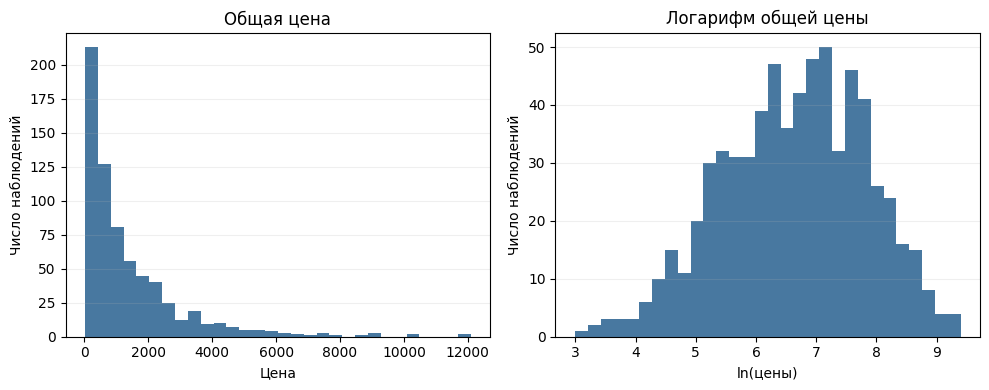

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].hist(model_data['total_price'], bins=30, color='#286090', alpha=0.85)
axes[0].set_title('Общая цена')
axes[0].set_xlabel('Цена')
axes[0].set_ylabel('Число наблюдений')
axes[0].grid(axis='y', alpha=0.2)
axes[1].hist(model_data['log_total_price'], bins=30, color='#286090', alpha=0.85)
axes[1].set_title('Логарифм общей цены')
axes[1].set_xlabel('ln(цены)')
axes[1].set_ylabel('Число наблюдений')
axes[1].grid(axis='y', alpha=0.2)
fig.tight_layout()
fig.savefig('price_distribution_simple.png', dpi=160, bbox_inches='tight')
plt.show()

### Корреляции и мультиколлинеарность

Для скрининга используется ориентир |r| ≥ 0,8: он помогает заметить почти дублирующие числовые признаки, но не является универсальным правилом. Для шести регрессоров считаются парные корреляции и VIF; значение выше 5 рассматривается как ориентировочный сигнал для проверки спецификации. Дополнительные кандидаты `product_score` и `volume` проверяются по их условному коэффициенту и изменению скорректированного R².


,Покупатели,Конкурент 1,Конкурент 2,Конкурент 3,Вес товара,Фото в карточке
Покупатели,1.000,-0.180,-0.018,-0.040,0.030,-0.059
Конкурент 1,-0.180,1.000,0.436,0.582,0.251,-0.069
Конкурент 2,-0.018,0.436,1.000,0.512,-0.051,-0.187
Конкурент 3,-0.040,0.582,0.512,1.000,0.016,-0.072
Вес товара,0.030,0.251,-0.051,0.016,1.000,-0.125
Фото в карточке,-0.059,-0.069,-0.187,-0.072,-0.125,1.000


Максимальная |r| между шестью регрессорами модели: 0.582


,Признак 1,Признак 2,Корреляция
0,unit_price,lag_price,0.9945


,Фактор,VIF
0,Покупатели,1.055
1,Конкурент 1,1.839
2,Конкурент 2,1.495
3,Конкурент 3,1.755
4,Вес товара,1.152
5,Фото в карточке,1.063


Все VIF ниже ориентировочного порога 5; сильная мультиколлинеарность в итоговой модели не выявлена.
Проверка дополнительных кандидатов по одному поверх итоговой модели:


,Дополнительный кандидат,p-value коэффициента,Скорректированный R²
0,Оценка товара,0.938,0.304
1,Логарифм объёма,0.712,0.305


Корреляция log(volume) с log(product_weight_g): 0.639


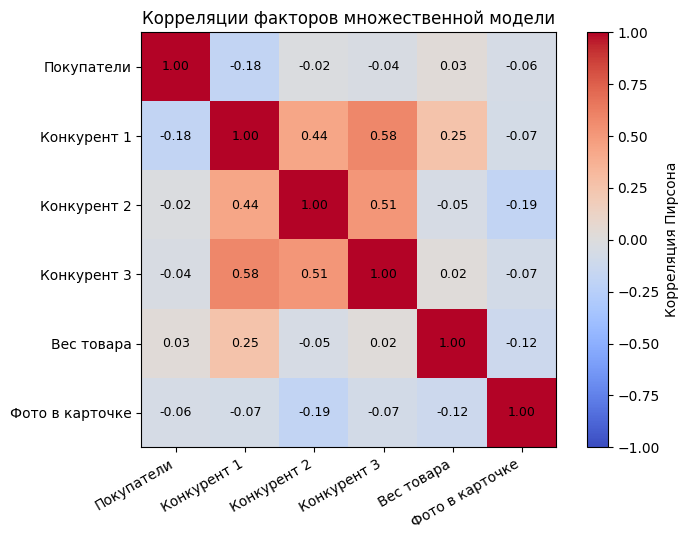

Корреляция unit_price и lag_price: 0.9945
95-й процентиль относительного расхождения total_price и unit_price × qty: 0.2832%
Максимальное относительное расхождение: 3.0583%


In [4]:
predictor_columns = [
    'log_customers', 'log_comp_1', 'log_comp_2', 'log_comp_3',
    'log_product_weight_g', 'product_photos_qty'
]
predictor_labels = {
    'log_customers': 'Покупатели',
    'log_comp_1': 'Конкурент 1',
    'log_comp_2': 'Конкурент 2',
    'log_comp_3': 'Конкурент 3',
    'log_product_weight_g': 'Вес товара',
    'product_photos_qty': 'Фото в карточке',
}
correlation_matrix = model_data[predictor_columns].corr()
correlation_display = correlation_matrix.rename(index=predictor_labels, columns=predictor_labels)
display(correlation_display.round(3))
upper_triangle = correlation_matrix.where(
    np.triu(np.ones(correlation_matrix.shape, dtype=bool), k=1)
)
max_pairwise_correlation = upper_triangle.abs().max().max()
print(f'Максимальная |r| между шестью регрессорами модели: {max_pairwise_correlation:.3f}')

numeric_corr = data.select_dtypes(include='number').corr()
high_corr_pairs = []
for i, left in enumerate(numeric_corr.columns):
    for right in numeric_corr.columns[i + 1:]:
        value = numeric_corr.loc[left, right]
        if abs(value) >= 0.8:
            high_corr_pairs.append({'Признак 1': left, 'Признак 2': right, 'Корреляция': value})
high_corr_table = pd.DataFrame(high_corr_pairs).sort_values('Корреляция', key=lambda x: x.abs(), ascending=False)
display(high_corr_table.round(4))

X_for_vif = sm.add_constant(model_data[predictor_columns])
vif_table = pd.DataFrame({
    'Фактор': [predictor_labels[column] for column in predictor_columns],
    'VIF': [variance_inflation_factor(X_for_vif.values, i + 1) for i in range(len(predictor_columns))],
})
display(vif_table.round(3))
print('Все VIF ниже ориентировочного порога 5; сильная мультиколлинеарность в итоговой модели не выявлена.')

screen_base = (
    'log_total_price ~ log_customers + log_comp_1 + log_comp_2 + log_comp_3 '
    '+ log_product_weight_g + product_photos_qty'
)
extra_screen_rows = []
for extra_term, label in [('product_score', 'Оценка товара'), ('log_volume', 'Логарифм объёма')]:
    candidate = smf.ols(screen_base + ' + ' + extra_term, data=model_data).fit()
    candidate_cluster = candidate.get_robustcov_results(
        cov_type='cluster', groups=pd.factorize(model_data.product_id)[0],
        use_correction=True, df_correction=True, use_t=True,
    )
    extra_index = candidate.model.exog_names.index(extra_term)
    extra_screen_rows.append({
        'Дополнительный кандидат': label,
        'p-value коэффициента': candidate_cluster.pvalues[extra_index],
        'Скорректированный R²': candidate.rsquared_adj,
    })
extra_screen = pd.DataFrame(extra_screen_rows)
print('Проверка дополнительных кандидатов по одному поверх итоговой модели:')
display(extra_screen.round(3))
print(f'Корреляция log(volume) с log(product_weight_g): {model_data[["log_volume", "log_product_weight_g"]].corr().iloc[0, 1]:.3f}')

fig, ax = plt.subplots(figsize=(7.4, 5.5))
image = ax.imshow(correlation_matrix, cmap='coolwarm', vmin=-1, vmax=1)
labels = [predictor_labels[column] for column in predictor_columns]
ax.set_xticks(range(len(labels)), labels=labels, rotation=30, ha='right')
ax.set_yticks(range(len(labels)), labels=labels)
for i in range(len(labels)):
    for j in range(len(labels)):
        ax.text(j, i, f'{correlation_matrix.iloc[i, j]:.2f}', ha='center', va='center', color='black', fontsize=9)
fig.colorbar(image, ax=ax, label='Корреляция Пирсона')
ax.set_title('Корреляции факторов множественной модели')
fig.tight_layout()
fig.savefig('predictor_correlations_simple.png', dpi=160, bbox_inches='tight')
plt.show()

unit_lag_correlation = data[['unit_price', 'lag_price']].corr().iloc[0, 1]
unit_qty_error = abs(data.total_price - data.unit_price * data.qty) / data.total_price
print(f'Корреляция unit_price и lag_price: {unit_lag_correlation:.4f}')
print(f'95-й процентиль относительного расхождения total_price и unit_price × qty: {unit_qty_error.quantile(0.95):.4%}')
print(f'Максимальное относительное расхождение: {unit_qty_error.max():.4%}')


## 3. Оценка модели и статистические проверки

Сначала сравниваются три сопоставимые модели, в каждой используются число покупателей, вес, число фотографий в карточке и цена одного конкурента. Затем оценивается множественная модель со всеми тремя ценами конкурентов и теми же контрольными признаками:

`ln(total_price) ~ ln(customers) + ln(comp_1) + ln(comp_2) + ln(comp_3) + ln(product_weight_g) + product_photos_qty`.

Для всех моделей применяются кластерные стандартные ошибки по товару. В расширенной модели отдельно проверяются индивидуальные коэффициенты, все шесть факторов модели и совместная гипотеза о нулевых коэффициентах трёх конкурентов. Уровень значимости — 5%.


In [5]:
product_groups = pd.factorize(model_data['product_id'])[0]
competitor_variables = ['comp_1', 'comp_2', 'comp_3']
candidate_rows = []
for competitor in competitor_variables:
    candidate_formula = (
        f'log_total_price ~ log_customers + log_{competitor} '
        '+ log_product_weight_g + product_photos_qty'
    )
    candidate_ols = smf.ols(candidate_formula, data=model_data).fit()
    candidate_cluster = candidate_ols.get_robustcov_results(
        cov_type='cluster', groups=product_groups, use_correction=True,
        df_correction=True, use_t=True,
    )
    coefficient_index = candidate_ols.model.exog_names.index(f'log_{competitor}')
    candidate_interval = candidate_cluster.conf_int(alpha=0.05)[coefficient_index]
    candidate_rows.append({
        'Конкурент': competitor,
        'Коэффициент': candidate_cluster.params[coefficient_index],
        'Кластерная SE': candidate_cluster.bse[coefficient_index],
        't': candidate_cluster.tvalues[coefficient_index],
        'p-value': candidate_cluster.pvalues[coefficient_index],
        '95%-ный интервал': f'[{candidate_interval[0]:.3f}; {candidate_interval[1]:.3f}]',
        'R²': candidate_ols.rsquared,
        'Скорректированный R²': candidate_ols.rsquared_adj,
    })
candidate_summary = pd.DataFrame(candidate_rows)
candidate_summary_display = candidate_summary.copy()
candidate_summary_display['p-value'] = candidate_summary['p-value'].map(lambda value: f'{value:.3g}')
display(candidate_summary_display.round({'Коэффициент': 4, 'Кластерная SE': 4, 't': 3, 'R²': 3, 'Скорректированный R²': 3}))

formula = (
    'log_total_price ~ log_customers + log_comp_1 + log_comp_2 '
    '+ log_comp_3 + log_product_weight_g + product_photos_qty'
)
ols_result = smf.ols(formula, data=model_data).fit()
cluster_result = ols_result.get_robustcov_results(
    cov_type='cluster', groups=product_groups, use_correction=True,
    df_correction=True, use_t=True,
)
confidence_intervals = cluster_result.conf_int(alpha=0.05)
results = pd.DataFrame({
    'Коэффициент': cluster_result.params,
    'Кластерная SE': cluster_result.bse,
    't': cluster_result.tvalues,
    'p-value': cluster_result.pvalues,
    'Нижняя граница 95%': confidence_intervals[:, 0],
    'Верхняя граница 95%': confidence_intervals[:, 1],
}, index=ols_result.model.exog_names)
result_order = [
    'log_customers', 'log_comp_1', 'log_comp_2', 'log_comp_3',
    'log_product_weight_g', 'product_photos_qty'
]
result_labels = [
    'Число покупателей', 'Цена конкурента 1', 'Цена конкурента 2',
    'Цена конкурента 3', 'Вес товара', 'Число фотографий'
]
results_display = results.loc[result_order].copy()
results_display.index = result_labels
results_display = results_display.round(4)
results_display['p-value'] = results.loc[result_order, 'p-value'].map(lambda value: f'{value:.3g}').to_numpy()
display(results_display)

competitor_restriction = np.zeros((3, len(cluster_result.params)))
competitor_restriction[:, 2:5] = np.eye(3)
competitor_test = cluster_result.f_test(competitor_restriction)
model_restriction = np.zeros((6, len(cluster_result.params)))
model_restriction[:, 1:] = np.eye(6)
model_test = cluster_result.f_test(model_restriction)
denominator_df = model_data.product_id.nunique() - 1
print(
    f'Совместный тест цен конкурентов: F(3, {denominator_df}) = '
    f'{float(np.asarray(competitor_test.fvalue).squeeze()):.2f}, '
    f'p-value = {float(np.asarray(competitor_test.pvalue).squeeze()):.3g}'
)
print(
    f'Тест модели в целом: F(6, {denominator_df}) = '
    f'{float(np.asarray(model_test.fvalue).squeeze()):.2f}, '
    f'p-value = {float(np.asarray(model_test.pvalue).squeeze()):.3g}'
)
print(f'R²: {ols_result.rsquared:.3f}')
print(f'Скорректированный R²: {ols_result.rsquared_adj:.3f}')
print(f'Число степеней свободы для кластерного t-критерия: {denominator_df}')


,Конкурент,Коэффициент,Кластерная SE,t,p-value,95%-ный интервал,R²,Скорректированный R²
0,comp_1,0.3706,0.1424,2.603,0.0121,[0.085; 0.656],0.244,0.239
1,comp_2,0.7236,0.1372,5.274,2.74e-06,[0.448; 0.999],0.303,0.299
2,comp_3,0.5389,0.1523,3.538,0.00087,[0.233; 0.845],0.263,0.258


,Коэффициент,Кластерная SE,t,p-value,Нижняя граница 95%,Верхняя граница 95%
Число покупателей,0.5503,0.0601,9.1554,2.39e-12,0.4297,0.6710
Цена конкурента 1,0.0244,0.1338,0.1825,0.856,-0.2443,0.2931
Цена конкурента 2,0.5937,0.1880,3.1583,0.00267,0.2163,0.9712
Цена конкурента 3,0.2238,0.2024,1.1058,0.274,-0.1825,0.6302
Вес товара,0.1522,0.0587,2.5911,0.0124,0.0343,0.2701
Число фотографий,0.1004,0.0694,1.4466,0.154,-0.0389,0.2397


Совместный тест цен конкурентов: F(3, 51) = 11.24, p-value = 8.98e-06
Тест модели в целом: F(6, 51) = 23.98, p-value = 2.91e-13
R²: 0.311
Скорректированный R²: 0.305
Число степеней свободы для кластерного t-критерия: 51


### Сравнение спецификаций и расширенная модель

В трёх отдельных моделях каждая цена конкурента положительно связана с общей ценой и значима при 5%. Во всех спецификациях дополнительно учтены покупатели, вес товара и число фотографий в карточке. Наибольший скорректированный `R²` у модели с `comp_2` — около 0,299.

В множественной модели все три цены включены одновременно. Индивидуальная положительная связь сохраняется у `comp_2` (`β = 0,594`, `p = 0,0027`); для `comp_1` (`p = 0,856`) и `comp_3` (`p = 0,274`) она не подтверждена. Цены конкурентов значимы совместно: `F(3, 51) = 11,24`, `p < 0,001`.

Также значимы число покупателей (`β = 0,550`, `p < 0,001`) и вес (`β = 0,152`, `p = 0,012`). Коэффициент числа фотографий положителен (`β = 0,100`), но незначим (`p = 0,154`, 95%-ный интервал включает ноль); поэтому самостоятельная связь с ценой не подтверждена. Модель в целом значима: `F(6, 51) = 23,98`, `p < 0,001`; `R² = 0,311`, скорректированный `R² = 0,305`.

Для итоговых шести факторов максимальная парная корреляция равна 0,582, а VIF лежат примерно между 1,06 и 1,84. Проверка кандидатов показала, что добавление `product_score` или `volume` по отдельности не повышает скорректированный `R²`; эти признаки оставлены за рамками компактной модели. `unit_price` и `qty` исключены из-за почти механической связи с целевой переменной, а `lag_price` коррелирует с `unit_price` на уровне 0,994.


In [6]:
effect_rows = []
for variable, label in [
    ('log_customers', 'Число покупателей'),
    ('log_comp_1', 'Цена конкурента 1'),
    ('log_comp_2', 'Цена конкурента 2'),
    ('log_comp_3', 'Цена конкурента 3'),
    ('log_product_weight_g', 'Вес товара'),
]:
    beta = results.loc[variable, 'Коэффициент']
    pvalue = results.loc[variable, 'p-value']
    effect_rows.append({
        'Признак': label,
        'Изменение фактора': 'Рост на 10%',
        'Модельная оценка изменения цены, %': (1.10 ** beta - 1) * 100,
        'p-value': f'{pvalue:.3g}',
        'Значима при 5%': 'Да' if pvalue < 0.05 else 'Нет',
    })
beta = results.loc['product_photos_qty', 'Коэффициент']
pvalue = results.loc['product_photos_qty', 'p-value']
effect_rows.append({
    'Признак': 'Число фотографий',
    'Изменение фактора': '+1 фотография',
    'Модельная оценка изменения цены, %': (np.exp(beta) - 1) * 100,
    'p-value': f'{pvalue:.3g}',
    'Значима при 5%': 'Да' if pvalue < 0.05 else 'Нет',
})
effect_table = pd.DataFrame(effect_rows)
display(effect_table.round(2))


,Признак,Изменение фактора,"Модельная оценка изменения цены, %",p-value,Значима при 5%
0,Число покупателей,Рост на 10%,5.39,2.39e-12,Да
1,Цена конкурента 1,Рост на 10%,0.23,0.856,Нет
2,Цена конкурента 2,Рост на 10%,5.82,0.00267,Да
3,Цена конкурента 3,Рост на 10%,2.16,0.274,Нет
4,Вес товара,Рост на 10%,1.46,0.0124,Да
5,Число фотографий,+1 фотография,10.56,0.154,Нет


## 4. Графики коэффициентов и остатков

График коэффициентов показывает оценки шести факторов и их 95%-ные кластерные интервалы; матрица корреляций относится к тем же факторам. График остатков и предсказанных значений служит визуальной диагностикой, а не формальным тестом всех предпосылок.


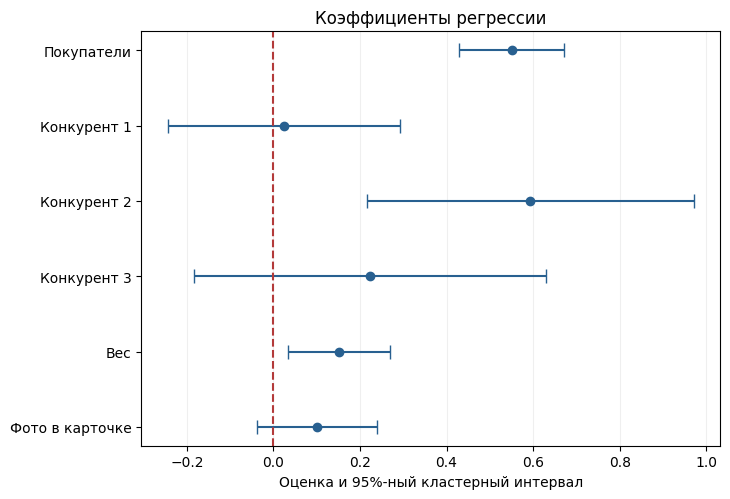

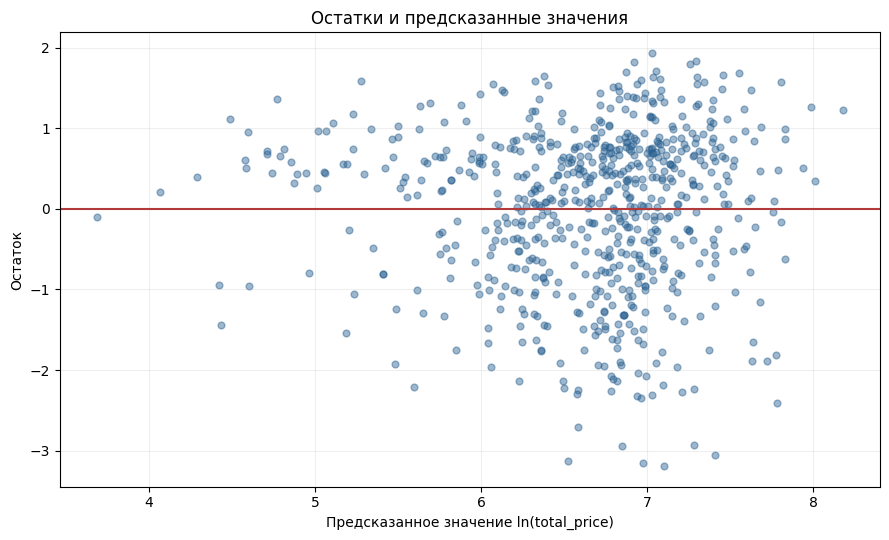

In [7]:
coefficient_labels = ['Покупатели', 'Конкурент 1', 'Конкурент 2', 'Конкурент 3', 'Вес', 'Фото в карточке']
coefficient_values = cluster_result.params[1:]
coefficient_intervals = confidence_intervals[1:]
positions = np.arange(len(coefficient_values))
fig, ax = plt.subplots(figsize=(7.4, 5.1))
ax.errorbar(
    coefficient_values,
    positions,
    xerr=np.vstack([
        coefficient_values - coefficient_intervals[:, 0],
        coefficient_intervals[:, 1] - coefficient_values,
    ]),
    fmt='o',
    capsize=5,
    color='#286090',
    ecolor='#286090',
)
ax.axvline(0, color='#b33a3a', linestyle='--', linewidth=1.5)
ax.set_yticks(positions, labels=coefficient_labels)
ax.invert_yaxis()
ax.set_xlabel('Оценка и 95%-ный кластерный интервал')
ax.set_title('Коэффициенты регрессии')
ax.grid(axis='x', alpha=0.2)
fig.tight_layout()
fig.savefig('coefficients_ci_simple.png', dpi=160, bbox_inches='tight')
plt.show()

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.scatter(ols_result.fittedvalues, ols_result.resid, alpha=0.45, color='#286090', s=24)
ax.axhline(0, color='#b33a3a', linewidth=1.5)
ax.set_title('Остатки и предсказанные значения')
ax.set_xlabel('Предсказанное значение ln(total_price)')
ax.set_ylabel('Остаток')
ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig('residuals_simple.png', dpi=160, bbox_inches='tight')
plt.show()
